R2 Score: 0.8489
RMSE: 1.8658


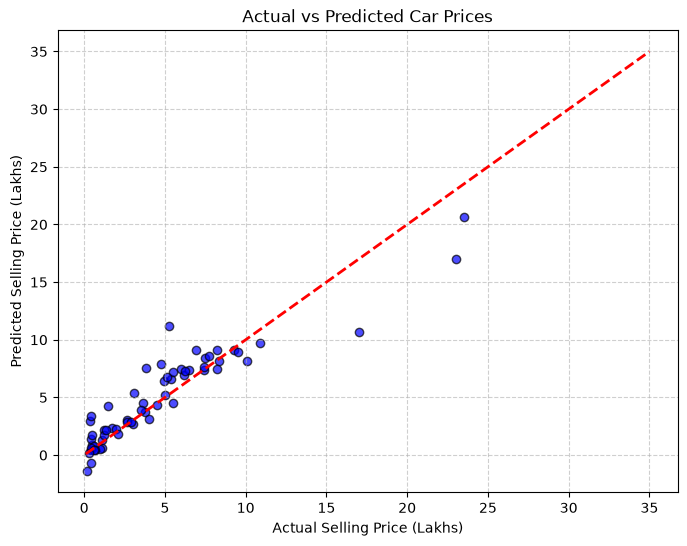

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Load Dataset
df = pd.read_csv('car data.csv')

# Feature Engineering: Calculate Car Age based on current year 2026
df['Car_Age'] = 2026 - df['Year']

# 2. Define Features (X) and Target (y)
X = df[['Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Car_Age', 'Owner']]
y = df['Selling_Price']

# 3. Preprocessing for categorical columns
categorical_features = ['Fuel_Type', 'Selling_type', 'Transmission']
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first'), categorical_features)
    ],
    remainder='passthrough'
)

# 4. Create Pipeline with Linear Regression Model
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Split data into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model
model_pipeline.fit(X_train, y_train)

# 5. Model Evaluation
y_pred = model_pipeline.predict(X_test)
print(f"R2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

# 6. Visualization and Saving the Plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.7, edgecolors='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.xlabel('Actual Selling Price (Lakhs)')
plt.ylabel('Predicted Selling Price (Lakhs)')
plt.title('Actual vs Predicted Car Prices')
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('actual_vs_predicted.png') # Plot save ho jayega GitHub ke liye
plt.show()